In [1]:
!uv pip install -q scikit-learn==1.9.1

In [2]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        # ipython = get_ipython()
        # # ipython.run_line_magic("load_ext", "cuml.accel")
        # ipython.run_line_magic("load_ext", "cudf.pandas")
        # print("🚀 GPU detected. RAPIDS accelerators successfully loaded!")
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        print("ℹ️ No GPU detected. Running on standard CPU mode.")
        return f"CORES: {os.cpu_count()}"

get_system_info()

ℹ️ No GPU detected. Running on standard CPU mode.


'CORES: 4'

In [3]:
# %load_ext cuml.accel
# %load_ext cudf.pandas

In [4]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [5]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

In [6]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import TargetEncoder as skTE
from sklearn.model_selection import KFold, train_test_split

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

warnings

<module 'warnings' from '/usr/lib/python3.13/warnings.py'>

In [7]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [8]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"data.csv")

## =================================================================================

TARGET, ID = 'satisfaction', 'id'

train[TARGET] = train[TARGET].map({True: 1, False: 0})
orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET, ID]]
num_cols  = [c for c in train.columns if c not in cat_cols+[TARGET, ID]]
base_cols = [c for c in train.columns if c not in [TARGET, ID]]

service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
    'Inflight entertainment', 'On-board service', 'Leg room service',
    'Baggage handling', 'Checkin service', 'Cleanliness'
]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

print(f"Frame type: {type(train)}\n")

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total base features: {len(base_cols)}")

Frame type: <class 'pandas.core.frame.DataFrame'>

Train shape: (699635, 22)
Test shape: (299844, 21)
Orig shape: (129880, 22)
Total Numerical: 17
Total Categorical: 4
Total base features: 21


In [9]:
train.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


In [10]:
# import pandas as pd
# from pandas.util import hash_pandas_object

# # Generate hashes
# hash1 = hash_pandas_object(train[base_cols], index=False)
# hash2 = hash_pandas_object(orig[base_cols], index=False)

# # Find rows in orig that are NOT present in train
# new_or_changed_rows = hash2.isin(hash1)

# # Get the actual data for those mismatched rows
# mismatched_orig_data = orig[new_or_changed_rows]
# display(mismatched_orig_data)

In [11]:
# train.head()

In [12]:
# train.describe().T

In [13]:
train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

satisfaction                            2
Type of Travel                          2
Customer Type                           2
Gender                                  2
Class                                   3
Baggage handling                        5
Gate location                           6
Departure/Arrival time convenient       6
Leg room service                        6
Checkin service                         6
On-board service                        6
Inflight wifi service                   6
Food and drink                          6
Online boarding                         6
Seat comfort                            6
Ease of Online booking                  6
Inflight entertainment                  6
Cleanliness                             6
Age                                    75
Departure Delay in Minutes            167
Arrival Delay in Minutes              168
Flight Distance                      3474
dtype: int64

In [14]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [15]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df.astype('float32'), on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [16]:
## -- DIGITS EXTRACTION --

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
combined = pd.concat([train, test, orig])

digit_cols = []
cols_select = ["Flight Distance"] #, "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"]

for col in cols_select:
    scaled = (combined[col].fillna(0) * (10**4)).astype('int64')
    for k in range(-4, 4):
        dig_col = f"{col}_dig_{k}"
        combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int32').astype('category')
        # combined[dig_col] = (combined[col].fillna(0) // (10**k) % 10).astype('int32').astype('category')
        digit_cols.append(dig_col)

train = combined.iloc[:train_len]
test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig = combined.iloc[-len(orig):]

# Check nunique, and find which ones are < 2
unique_counts = train[digit_cols].nunique()
drop_cols = unique_counts[unique_counts < 2].index.tolist()

# update digit cols for keep
digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# drop constant features
train = train.drop(columns=drop_cols)
test  = test.drop(columns=drop_cols)
orig  = orig.drop(columns=drop_cols)

del combined
print(f"Total digit features: {len(digit_cols)}\n")

train[digit_cols].nunique()

Total digit features: 4



Flight Distance_dig_3     5
Flight Distance_dig_0    10
Flight Distance_dig_1    10
Flight Distance_dig_2    10
dtype: int64

In [17]:
# ## -- Cyclic encoding --

# for df in [train, test]:
#     for p in [8, 12, 24]:
#         df[f"sleep_hours_sin_{p}"] = np.sin(2 * np.pi * df["sleep_hours"] / p).astype("float32")
#         df[f"sleep_hours_cos_{p}"] = np.cos(2 * np.pi * df["sleep_hours"] / p).astype("float32")

In [18]:
## -- NUMERIC TO CATEGORY for TargetEncoding -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig])
## ------------------------------------------------------------

# -- Duplicate Nums as Cats --
nums_to_cats = []
select_nc = ["Flight Distance"] # "Arrival Delay in Minutes", "Departure Delay in Minutes"]
for c in tqdm(select_nc, desc="nums_to_cats"):
    new_cat = f"{c}_cat_"
    combined[new_cat] = (pd.factorize(combined[c])[0]).astype('int32')
    # combined[n] = combined[n].astype('category')
    nums_to_cats.append(new_cat)

FEATURES = list(set(FEATURES + nums_to_cats))

## ------------------------------------------------------------
train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Features after operation:", len(FEATURES))

Features before operation: 25


nums_to_cats:   0%|          | 0/1 [00:00<?, ?it/s]

Features after operation: 26


In [19]:
# ## -- Frequency encoding -- ⚠️
# freq_cols = []

# combined = pd.concat([train, test], ignore_index=True)

# select_freq = ["Flight Distance"]
# #, "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"]

# print("\nCreating frequencies (Safe Global Mapping)...")
# for col in select_freq:
#     n = f"_freq_{col}"
#     print(f"⧗ {n}", end="")

#     # Calculate frequencies using ONLY train
#     freq_map = train[col].value_counts(dropna=False, normalize=False).to_dict()

#     # Map the training-derived frequencies across all datasets safely
#     train[n] = train[col].map(freq_map).fillna(0).astype("float32")
#     test[n] = test[col].map(freq_map).fillna(0).astype("float32")
#     orig[n] = orig[col].map(freq_map).fillna(0).astype("float32")

#     freq_cols.append(n)
#     print()

# # num_cols = list(set(num_cols + freq_cols))
# FEATURES = list(set(FEATURES + freq_cols))

# print(f"\n *** Total frequency features: {len(freq_cols)}")

In [20]:
## -- Factorize cat_cols -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig])
## ------------------------------------------------------------------------
for c in tqdm(cat_cols, desc="factorize_cats"):
    combined[c] = (pd.factorize(combined[c])[0]).astype('int32')
## ------------------------------------------------------------------------
GROUP_COLS = []
grouper  = 'Flight Distance'
agg_cols = ['Class', 'Type of Travel'] + service_cols

for col in agg_cols:
    g_col = f"{col}_{grouper.split(' ')[0]}_GROUPBY".replace(" ", "")
    combined[f"{g_col}_mean"] = combined.groupby([grouper])[col].transform('mean')
    combined[f"{g_col}_std"] = combined.groupby([grouper])[col].transform('std')
    # combined[f"{g_col}_skew"] = combined.groupby(['Flight Distance'])[col].transform('skew')
    GROUP_COLS.append(g_col)

# grouper2 = 'Age'
# for col in agg_cols:
#     g_col = f"{col}_{grouper2}_GROUPBY".replace(" ", "")
#     combined[f"{g_col}_mean"] = combined.groupby(['Age'])[col].transform('mean')
#     # combined[f"{g_col}_std"] = combined.groupby(['Age'])[col].transform('std')
#     # combined[f"{g_col}_skew"] = combined.groupby(['Flight Distance'])[col].transform('skew')
#     GROUP_COLS.append(g_col)

FEATURES = list(set(FEATURES + GROUP_COLS))
## ------------------------------------------------------------------------
for c in tqdm(cat_cols, desc="categorize_cats"):
    combined[c] = combined[c].astype("category")

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Group Cols:", len(GROUP_COLS))
print("Total features after operation:", len(FEATURES))

Total features before operation: 26


factorize_cats:   0%|          | 0/4 [00:00<?, ?it/s]

categorize_cats:   0%|          | 0/4 [00:00<?, ?it/s]

Group Cols: 15
Total features after operation: 41


In [21]:
# ## FLOOR/BIN FEATURES -- ⚠️
# floor_cols = []

# combined = pd.concat([train, test, orig])

# for f in tqdm([1000], desc='Floor features (bins)'):
#     # print(f, end='-> ')
#     for c in ['Flight Distance']:
#         f_name = f"{c}_floor{f}"
#         print(f" ⧗ {f_name}", end='... ')
#         combined[f_name] = (combined[c].fillna(0) // f).astype('int32').astype('category')
#         floor_cols.append(f_name)
#         print()

# # for f in tqdm([10], desc='Floor features (bins)'):
# #     # print(f, end='-> ')
# #     for c in ['Departure Delay in Minutes', 'Arrival Delay in Minutes']:
# #         f_name = f"{c}_//_{f}"
# #         print(f" ⧗ {f_name}", end='... ')
# #         combined[f_name] = (combined[c] // f).astype('int32')
# #         floor_cols.append(f_name)
# #         print()

# for f in tqdm([10], desc='Floor features (bins)'):
#     # print(f, end='-> ')
#     for c in ['Age']:
#         age_n = f"{c}_floor{f}"
#         print(f" ⧗ {age_n}", end='... ')
#         combined[age_n] = (combined[c] // f).astype('int32').astype('category')
#         floor_cols.append(age_n)
#         print()

# # combined[f"age{f}_X_dist1000"] = combined[age_n] * combined[f_name]

# # FEATURES = list(set(FEATURES + floor_cols))

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print(f"\n*** Total floor features: {len(floor_cols)}")

# print(train[floor_cols].nunique(dropna=False))

In [22]:
## -- INTERACTIONS -- ⚠️

INTER = []

combo_select = [c for c in base_cols if train[c].nunique() < 10] + ['Flight Distance_//_250', 'Age_//_10']
comb = [c for c in num_cols if (train[c].nunique() < 10) and (c in base_cols)]

combined = pd.concat([train, test, orig], ignore_index=True)
# ------------------------------------------------------------------------
combo_2_1 = list(itertools.combinations(cat_cols, 2))
for c1, c2 in tqdm(combo_2_1, desc='Pairwise Sync Encoding'):
    n_col = f"Bi_{c1}_X_{c2}".replace(" ", "")
    combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
    combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
    # combined[n_col] = combined[n_col].astype('category')
    INTER.append(n_col)

combo_3_1 = list(itertools.combinations(cat_cols, 3)) # + [age_n]
for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise Sync Encoding'):
    n_col = f"Tri_{c1}_X_{c2}_X_{c3}".replace(" ", "")
    combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str) + '_' + combined[c3].astype(str)
    combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
    # combined[n_col] = combined[n_col].astype('category')
    INTER.append(n_col)

# combo_4_1 = list(itertools.combinations(cat_cols, 4))
# for c1, c2, c3, c4 in tqdm(combo_4_1, desc='Quadwise Sync Encoding'):
#     n_col = f"Quad_{c1}_X_{c2}_X_{c3}_X_{c4}".replace(" ", "")
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str) + '_' + combined[c3].astype(str) + '_' + combined[c4].astype(str)
#     combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)

# combo_1_to_many = list(itertools.product(cat_cols, [age_n]))
# for c1, c2 in tqdm(combo_1_to_many, desc='One-2-Many Sync Encoding'):
#     n_col = f"Bi2_{c1}_X_{c2}".strip()
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
#     combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)
# ------------------------------------------------------------------------

for n_col in INTER:
    train[n_col] = combined[n_col].iloc[:train_len].values
    test[n_col]  = combined[n_col].iloc[train_len:train_len + test_len].values
    orig[n_col]  = combined[n_col].iloc[train_len + test_len:].values

print(f"Total Interaction Features: {INTER}")

del combined
# train[INTER].head()

Pairwise Sync Encoding:   0%|          | 0/6 [00:00<?, ?it/s]

Triplewise Sync Encoding:   0%|          | 0/4 [00:00<?, ?it/s]

Total Interaction Features: ['Bi_Gender_X_CustomerType', 'Bi_Gender_X_TypeofTravel', 'Bi_Gender_X_Class', 'Bi_CustomerType_X_TypeofTravel', 'Bi_CustomerType_X_Class', 'Bi_TypeofTravel_X_Class', 'Tri_Gender_X_CustomerType_X_TypeofTravel', 'Tri_Gender_X_CustomerType_X_Class', 'Tri_Gender_X_TypeofTravel_X_Class', 'Tri_CustomerType_X_TypeofTravel_X_Class']


In [23]:
# # ==========================================
# # 2. HIGH-IMPACT DOMAIN INTERACTIONS (AUC BOOST) ⚠️
# # ==========================================

# combined = pd.concat([train, test, orig])

# service_cols = [
#     'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
#     'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
#     'Inflight entertainment', 'On-board service', 'Leg room service',
#     'Baggage handling', 'Checkin service', 'Cleanliness'
# ]

# # A. Total Delay & Delay Discrepancy
# # Tree models easily split on raw values, but explicit sums and differences reduce required tree depth
# # combined['Total_Delay'] = combined['Departure Delay in Minutes'].fillna(0) + combined['Arrival Delay in Minutes'].fillna(0)
# # combined['Is_Delayed'] = (combined['Total_Delay'] > 0).astype('int8').astype('category')
# # combined['Delay_Recovered'] = combined['Departure Delay in Minutes'].fillna(0) - combined['Arrival Delay in Minutes'].fillna(0)

# # # B. Aggregated Service Experience Scores (Crucial for Passenger Satisfaction datasets)
# # # Capturing the holistic experience mathematically
# combined['Total_Service_Score'] = combined[service_cols].sum(axis=1)
# combined['Mean_Service_Score']  = combined[service_cols].mean(axis=1)
# combined['Variance_Service_Score'] = combined[service_cols].var(axis=1).astype('float32')

# # # Segmenting critical service groups
# booking_flow = ['Inflight wifi service', 'Ease of Online booking', 'Online boarding']
# comfort_flow = ['Seat comfort', 'Food and drink', 'Leg room service', 'Cleanliness']
# combined['Digital_Experience_Score'] = combined[booking_flow].mean(axis=1)
# combined['Physical_Comfort_Score'] = combined[comfort_flow].mean(axis=1)

# # # Count of zero-scores (often represents "Not Applicable" or an extreme pain point)
# # combined['Count_Zero_Services'] = (combined[service_cols] == 0).sum(axis=1).astype('int8')
# # combined['Count_High_Services'] = (combined[service_cols] >= 4).sum(axis=1).astype('int8')

# # # C. Distance vs. Age Groupings
# # combined['Distance_per_Year_of_Age'] = combined['Flight Distance'] / (combined['Age'] + 1)

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print("Arithmetric features ready")

In [24]:
# ## -- base_margin >>> LOAD OTHER MODEL PREDICTIONS --

# link = "/kaggle/input/notebooks/sylvesterdalmeida/ps6e10-tabpfn-se-airline/"
# trn_base_margin = np.load(link+"oof_TABPFNe2loc_959837.npy")
# tst_base_margin = np.load(link+"test_TABPFNe2loc_959837.npy")

# # eps = 1e-15
# # for df in [train, test]:
# #     pos_probs = np.clip(df[base_margin].values, eps, 1 - eps)
# #     logits = np.log(pos_probs / (1 - pos_probs))
# #     # df[f"{base_margin}_logits"] = logits
# #     df[base_margin] = logits

# trn_base_margin.shape, tst_base_margin.shape

In [25]:
## -- extra_feature >>> LOAD ORIGINAL OUTPUTS --
orig_feature = f"ORIG_{TARGET}_preds"

link = "/kaggle/input/notebooks/sylvesterdalmeida/ps6e10-autogluon-original-airline/"
train[orig_feature] = np.load(link+"AG_preds/ag_best_satisfaction_trn.npy")
test[orig_feature]  = np.load(link+"AG_preds/ag_best_satisfaction_tst.npy")

# EPS = 1e-15
# for df in [train, test]:
#     pos_probs = np.clip(df[orig_feature].values, EPS, 1 - EPS)
#     logits = np.log(pos_probs / (1 - pos_probs))
#     # df[orig_feature] = logits
#     df[f"{orig_feature}_logits"] = logits

train.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction,Flight Distance_dig_0,Flight Distance_dig_1,Flight Distance_dig_2,Flight Distance_dig_3,Flight Distance_cat_,Class_Flight_GROUPBY_mean,Class_Flight_GROUPBY_std,TypeofTravel_Flight_GROUPBY_mean,TypeofTravel_Flight_GROUPBY_std,Inflightwifiservice_Flight_GROUPBY_mean,Inflightwifiservice_Flight_GROUPBY_std,Departure/Arrivaltimeconvenient_Flight_GROUPBY_mean,Departure/Arrivaltimeconvenient_Flight_GROUPBY_std,EaseofOnlinebooking_Flight_GROUPBY_mean,EaseofOnlinebooking_Flight_GROUPBY_std,Gatelocation_Flight_GROUPBY_mean,Gatelocation_Flight_GROUPBY_std,Foodanddrink_Flight_GROUPBY_mean,Foodanddrink_Flight_GROUPBY_std,Onlineboarding_Flight_GROUPBY_mean,Onlineboarding_Flight_GROUPBY_std,Seatcomfort_Flight_GROUPBY_mean,Seatcomfort_Flight_GROUPBY_std,Inflightentertainment_Flight_GROUPBY_mean,Inflightentertainment_Flight_GROUPBY_std,On-boardservice_Flight_GROUPBY_mean,On-boardservice_Flight_GROUPBY_std,Legroomservice_Flight_GROUPBY_mean,Legroomservice_Flight_GROUPBY_std,Baggagehandling_Flight_GROUPBY_mean,Baggagehandling_Flight_GROUPBY_std,Checkinservice_Flight_GROUPBY_mean,Checkinservice_Flight_GROUPBY_std,Cleanliness_Flight_GROUPBY_mean,Cleanliness_Flight_GROUPBY_std,Bi_Gender_X_CustomerType,Bi_Gender_X_TypeofTravel,Bi_Gender_X_Class,Bi_CustomerType_X_TypeofTravel,Bi_CustomerType_X_Class,Bi_TypeofTravel_X_Class,Tri_Gender_X_CustomerType_X_TypeofTravel,Tri_Gender_X_CustomerType_X_Class,Tri_Gender_X_TypeofTravel_X_Class,Tri_CustomerType_X_TypeofTravel_X_Class,ORIG_satisfaction_preds
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0,0,0,0,0.0,4,9,6,0,0,0.271978,0.552783,0.491758,0.500276,2.821429,1.262509,3.704670,1.302576,2.649725,1.228770,2.951923,1.209384,3.440934,1.312023,3.142857,1.329562,3.505495,1.324812,3.458791,1.320020,3.565934,1.196530,3.166209,1.349965,3.831044,1.189256,3.563187,1.185129,3.510989,1.315400,0,0,0,0,0,0,0,0,0,0,0.263970
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1,0,1,1,1.0,1,5,6,0,1,0.451172,0.611401,0.606192,0.488649,2.735716,1.198831,2.770772,1.549735,2.787389,1.252268,3.085591,1.148752,3.052811,1.317680,3.054405,1.270909,3.223310,1.327337,3.147507,1.355722,3.153654,1.319712,3.228318,1.358706,3.540633,1.128876,3.078306,1.281174,3.099476,1.326101,1,1,1,1,1,1,1,1,1,1,0.999079
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0,0,0,0,0.0,1,7,3,1,2,0.451827,0.545901,0.591362,0.491991,2.865449,1.210122,3.637874,1.362107,2.850498,1.261582,2.973422,1.208384,3.267442,1.372381,3.335548,1.286186,3.588040,1.340421,3.360465,1.338524,3.674419,1.002647,3.456811,1.095580,3.845515,0.901683,3.737542,1.043586,3.440199,1.370201,0,0,0,0,0,0,0,0,0,0,0.000210
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,1,0,0,0,0.0,6,1,6,1,3,0.737403,0.528376,0.720930,0.448759,2.737403,1.291559,3.344961,1.398764,2.868217,1.346071,2.957364,1.322096,3.414729,1.289552,3.484496,1.251091,3.777132,1.254571,3.698643,1.292851,3.795543,1.139988,3.724806,1.222107,3.968992,0.987314,3.644380,1.120520,3.586240,1.251313,1,2,2,0,0,0,2,2,2,0,0.000148
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0,1,1,0,0.0,1,8,4,0,4,0.436526,0.618267,0.632517,0.482388,2.768374,1.268705,2.918708,1.461153,2.824053,1.302686,3.189310,1.169006,3.241648,1.362241,3.074610,1.285370,3.358575,1.313908,3.335189,1.357135,3.109131,1.323531,3.236080,1.330523,3.467706,1.107169,2.889755,1.290600,3.250557,1.356525,2,3,0,2,2,2,3,3,3,2,0.012686


In [26]:
train.nunique()[-20:]

On-boardservice_Flight_GROUPBY_std            3326
Legroomservice_Flight_GROUPBY_mean            2469
Legroomservice_Flight_GROUPBY_std             3308
Baggagehandling_Flight_GROUPBY_mean           2448
Baggagehandling_Flight_GROUPBY_std            3330
Checkinservice_Flight_GROUPBY_mean            2442
Checkinservice_Flight_GROUPBY_std             3314
Cleanliness_Flight_GROUPBY_mean               2461
Cleanliness_Flight_GROUPBY_std                3328
Bi_Gender_X_CustomerType                         4
Bi_Gender_X_TypeofTravel                         4
Bi_Gender_X_Class                                6
Bi_CustomerType_X_TypeofTravel                   4
Bi_CustomerType_X_Class                          6
Bi_TypeofTravel_X_Class                          6
Tri_Gender_X_CustomerType_X_TypeofTravel         8
Tri_Gender_X_CustomerType_X_Class               12
Tri_Gender_X_TypeofTravel_X_Class               12
Tri_CustomerType_X_TypeofTravel_X_Class         12
ORIG_satisfaction_preds        

# ML TRAINING

In [27]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=300_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

_ = [c for c in train_X.columns if c not in [ID, TARGET]]
FEATURES = list(set(_))

print(f"Train shape {train_X.shape}")
# train_X.head()

(699635, 68) <class 'pandas.core.frame.DataFrame'>
Train shape (699635, 68)


In [28]:
## -- Handle optional original table aggregations
USE_ORIGINAL = False

import_cols = base_cols # ['Flight Distance'] + cat_cols + service_cols

if USE_ORIGINAL: # try 'std' again later ⚠️
    aggs_ = ["mean", "count"]  # "mean", "count", "std", "skew", "nunique",
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features=import_cols,
        aggs=aggs_, #fill_nan=True
    )
    x_test, _ = original_TE(
        orig, test, target=TARGET, features=import_cols,
        aggs=aggs_, #fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int32")
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype("int32")

print(X.shape, type(X))
X.head()

(699635, 67) <class 'pandas.core.frame.DataFrame'>


,Gate location,Food and drink,EaseofOnlinebooking_Flight_GROUPBY_std,Bi_TypeofTravel_X_Class,Customer Type,Onlineboarding_Flight_GROUPBY_std,Seatcomfort_Flight_GROUPBY_mean,Cleanliness_Flight_GROUPBY_mean,Bi_Gender_X_TypeofTravel,Flight Distance_dig_2,Inflightwifiservice_Flight_GROUPBY_mean,Flight Distance_cat_,Inflightentertainment_Flight_GROUPBY_mean,Legroomservice_Flight_GROUPBY_mean,Legroomservice_Flight_GROUPBY_std,Flight Distance_dig_0,Gender,Class_Flight_GROUPBY_mean,Departure/Arrival time convenient,Online boarding,ORIG_satisfaction_preds,Foodanddrink_Flight_GROUPBY_mean,Class_Flight_GROUPBY_std,Departure/Arrivaltimeconvenient_Flight_GROUPBY_std,TypeofTravel_Flight_GROUPBY_mean,Foodanddrink_Flight_GROUPBY_std,Tri_Gender_X_CustomerType_X_Class,EaseofOnlinebooking_Flight_GROUPBY_mean,Tri_Gender_X_TypeofTravel_X_Class,Age,Checkin service,Inflight entertainment,Ease of Online booking,Bi_CustomerType_X_Class,On-board service,Arrival Delay in Minutes,Departure Delay in Minutes,Baggagehandling_Flight_GROUPBY_mean,On-boardservice_Flight_GROUPBY_mean,Bi_Gender_X_CustomerType,Tri_Gender_X_CustomerType_X_TypeofTravel,Inflightwifiservice_Flight_GROUPBY_std,Baggage handling,Onlineboarding_Flight_GROUPBY_mean,Leg room service,Flight Distance_dig_3,Departure/Arrivaltimeconvenient_Flight_GROUPBY_mean,Tri_CustomerType_X_TypeofTravel_X_Class,On-boardservice_Flight_GROUPBY_std,Inflightentertainment_Flight_GROUPBY_std,Baggagehandling_Flight_GROUPBY_std,Checkinservice_Flight_GROUPBY_mean,Gatelocation_Flight_GROUPBY_std,Cleanliness_Flight_GROUPBY_std,Class,TypeofTravel_Flight_GROUPBY_std,Type of Travel,Checkinservice_Flight_GROUPBY_std,Flight Distance_dig_1,Bi_CustomerType_X_TypeofTravel,Flight Distance,Inflight wifi service,Gatelocation_Flight_GROUPBY_mean,Seat comfort,Cleanliness,Bi_Gender_X_Class,Seatcomfort_Flight_GROUPBY_std
0,3,1,1.228770,0,0,1.329562,3.505495,3.510989,0,6,2.821429,0,3.458791,3.166209,1.349965,4,0,0.271978,4,4,0.263970,3.440934,0.552783,1.302576,0.491758,1.312023,0,2.649725,0,36,3,1,4,0,3,0.0,0,3.831044,3.565934,0,0,1.262509,4,3.142857,4,0,3.704670,0,1.196530,1.320020,1.189256,3.563187,1.209384,1.315400,0,0.500276,0,1.185129,9,0,694,4,2.951923,1,1,0,1.324812
1,5,5,1.252268,1,0,1.270909,3.223310,3.099476,1,6,2.735716,1,3.147507,3.228318,1.358706,1,1,0.451172,5,4,0.999079,3.052811,0.611401,1.549735,0.606192,1.317680,1,2.787389,1,56,4,5,5,1,5,0.0,0,3.540633,3.153654,1,1,1.198831,5,3.054405,5,0,2.770772,1,1.319712,1.355722,1.128876,3.078306,1.148752,1.326101,1,0.488649,1,1.281174,5,1,651,5,3.085591,4,3,1,1.327337
2,5,3,1.261582,0,0,1.286186,3.588040,3.440199,0,3,2.865449,2,3.360465,3.456811,1.095580,1,0,0.451827,4,3,0.000210,3.267442,0.545901,1.362107,0.591362,1.372381,0,2.850498,0,31,5,3,2,0,4,0.0,0,3.845515,3.674419,0,0,1.210122,4,3.335548,3,1,3.637874,0,1.002647,1.338524,0.901683,3.737542,1.208384,1.370201,0,0.491991,0,1.043586,7,0,1371,3,2.973422,3,3,0,1.340421
3,3,3,1.346071,0,0,1.251091,3.777132,3.586240,2,6,2.737403,3,3.698643,3.724806,1.222107,6,1,0.737403,5,3,0.000148,3.414729,0.528376,1.398764,0.720930,1.289552,2,2.868217,2,10,4,3,3,0,4,0.0,0,3.968992,3.795543,1,2,1.291559,3,3.484496,5,1,3.344961,0,1.139988,1.292851,0.987314,3.644380,1.322096,1.251313,0,0.448759,0,1.120520,1,0,1616,3,2.957364,3,3,2,1.254571
4,4,5,1.302686,2,1,1.285370,3.358575,3.250557,3,4,2.768374,4,3.335189,3.236080,1.330523,1,0,0.436526,4,3,0.012686,3.241648,0.618267,1.461153,0.632517,1.362241,3,2.824053,3,23,3,5,3,2,5,0.0,5,3.467706,3.109131,2,3,1.268705,5,3.074610,4,0,2.918708,2,1.323531,1.357135,1.107169,2.889755,1.169006,1.356525,0,0.482388,1,1.290600,8,2,481,3,3.189310,5,5,0,1.313908


In [29]:
# ## -- Reduce data memory --

# def reduce_memory(df):
#     # Use copy() if you want to avoid modifying the original dataframe in place
#     # df = df.copy()

#     old_size = df.memory_usage(deep=True).sum() / (1024 * 1024)

#     for c in tqdm(df.columns, desc='Reducing memory...'):
#         col_type = df[c].dtype

#         # Check if type is numeric (integers and floats)
#         if np.issubdtype(col_type, np.integer):
#             df[c] = pd.to_numeric(df[c], downcast='integer')
#         elif np.issubdtype(col_type, np.floating):
#             df[c] = pd.to_numeric(df[c], downcast='float')
#         # Optional: Convert object types with low cardinality to category
#         elif col_type == object or col_type.name == 'category':
#             if df[c].nunique() < len(df[c]) * 0.5:  # If less than 50% unique values
#                 df[c] = df[c].astype('category')

#     new_size = df.memory_usage(deep=True).sum() / (1024 * 1024)
#     print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f} MB\n")

#     return df

# X = reduce_memory(X)
# X_test = reduce_memory(X_test)
# # orig = reduce_memory(orig)

# print(f"Data memory reduced!")
# gc.collect()

In [30]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 699635 entries, 0 to 699634
Data columns (total 67 columns):
 #   Column                                               Non-Null Count   Dtype   
---  ------                                               --------------   -----   
 0   Gate location                                        699635 non-null  int64   
 1   Food and drink                                       699635 non-null  int64   
 2   EaseofOnlinebooking_Flight_GROUPBY_std               699633 non-null  float64 
 3   Bi_TypeofTravel_X_Class                              699635 non-null  int32   
 4   Customer Type                                        699635 non-null  category
 5   Onlineboarding_Flight_GROUPBY_std                    699633 non-null  float64 
 6   Seatcomfort_Flight_GROUPBY_mean                      699635 non-null  float64 
 7   Cleanliness_Flight_GROUPBY_mean                      699635 non-null  float64 
 8   Bi_Gender_X_TypeofTravel                         

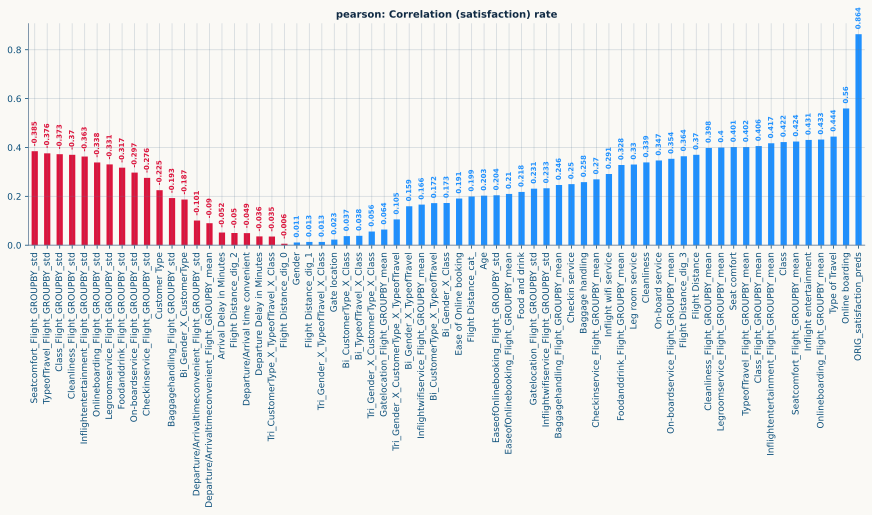

In [31]:
corr_type = ['pearson', 'spearman'][0]

plt.figure(figsize=(15, 4))
corr_df = X.corrwith(train_X[TARGET], method=corr_type).sort_values()
corr_df.abs().plot(kind='bar', color=[CRIM if c < 0 else BLUE for c in corr_df.values])
for i, v in enumerate(corr_df.values):
    plt.text(
        i, np.abs(v) + 0.02, np.round(v, 3),
        size=7, weight='semibold', color=CRIM if v < 0 else BLUE,
        va='bottom', ha='center', rotation=90,
    )

plt.title(f"{corr_type}: Correlation ({TARGET}) rate")
plt.show()

In [32]:
try:
    import optuna
except ModuleNotFoundError:
    !pip install optuna -q
    import optuna

def objective(trial):

    FOLDS = 5
    skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

    _id = 'gbt' # 'gbt' 'los' 'gra'
    model_name = all_models[_id][0]
    params = all_models[_id][1].copy()
    params.update({
        # 'sampling_method': "gradient_based",
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0, step=0.001),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0, step=0.001),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 3.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 5.0, log=True),
        'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
        'early_stopping_rounds': 100,
        'random_state': 42,
        'learning_rate': 0.01,
    })

    fold_scores = []

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
        X_tr = X.iloc[tr_idx].copy()
        X_val = X.iloc[val_idx].copy()
        y_tr = y.iloc[tr_idx]
        y_val = y.iloc[val_idx]
        X_tst = X_test.copy()

        # Target encoding
        if CFG.TE:
            te_cols = nums_to_cats + INTER # + floor_cols
            smooth = 'auto'
            # print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
            TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
            tr_enc = TE.fit_transform(X_tr[te_cols], y_tr)
            va_enc = TE.transform(X_val[te_cols])
            ts_enc = TE.transform(X_tst[te_cols])

            te_names = [f"TE{smooth}_{col}" for col in te_cols]
            X_tr[te_names]  = tr_enc
            X_val[te_names] = va_enc
            X_tst[te_names] = ts_enc

            combos_to_drop = te_cols

            X_tr  = X_tr.drop(columns=combos_to_drop)
            X_val = X_val.drop(columns=combos_to_drop)
            X_tst = X_tst.drop(columns=combos_to_drop)
        # ------------------------------------------------------------------------------
        if fold == 1: print(f"{model_name} | train={X_tr.shape}, valid={X_val.shape}\n")
        # print("#"*16)
        # print(f"### Fold {fold}/{FOLDS} ...")
        # print("#"*16)

        trn_margin = trn_base_margin[tr_idx] if 'trn_base_margin' in globals() else None
        val_margin = trn_base_margin[val_idx] if 'trn_base_margin' in globals() else None
        tst_margin = tst_base_margin if 'tst_base_margin' in globals() else None

        model = xgb.XGBClassifier(**params)
        model.fit(
            X_tr, y_tr, verbose=False,
            eval_set = [(X_tr, y_tr), (X_val, y_val)],
            base_margin = trn_margin,
            # base_margin_eval_set = [trn_margin, val_margin],
        )

        val_preds = model.predict_proba(X_val, base_margin=val_margin)[:, 1]
        fold_scores.append(roc_auc_score(y_val, val_preds))

        torch.cuda.empty_cache()

    avg_auc = np.round(np.mean(fold_scores), 6)
    std_auc = np.round(np.std(fold_scores), 6)
    print(f"AVG score: {Fore.BLUE}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")

    return avg_auc

print("Optuna search function ready!")

Optuna search function ready!


In [33]:
# # ==========================================
# # RUN THE OPTUNA SEARCH
# # ==========================================
# opt_study = optuna.create_study(direction="maximize")
# opt_study.optimize(objective, n_trials=30, timeout=3600)

# print("\n💥 Optimization Finished!")
# print(f"Best OOF AUC: {opt_study.best_value:.6f}")
# print("Best Params:", opt_study.best_params)

In [34]:
if 'opt_study' in globals():
    print(f"Best OOF AUC: {study.best_value:.6f}")
    print("Best Params:", study.best_params)

In [35]:
## -- Visualize parameter importance
if 'opt_study' in globals():
    optuna.visualization.plot_param_importances(opt_study).show()
    optuna.visualization.plot_slice(opt_study).show()
    optuna.visualization.plot_optimization_history(opt_study).show()

In [36]:
class CFG:
    FOLDS = 5
    SEED  = 42
    TE = True if 'nums_to_cats' in globals() else False
    ES = 20 # 30, 50
    VERB = 1 # 1, 2

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = "HIST_"
print(f"\n🚀 Training {model_name} with {FOLDS } Folds")

oof_preds  = np.zeros(len(train_X))
test_preds = np.zeros(len(X_test))

fold_scores = []
best_iterations = []
feat_importances = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr = X.iloc[tr_idx].copy()
    X_val = X.iloc[val_idx].copy()
    y_tr = y.iloc[tr_idx]
    y_val = y.iloc[val_idx]
    X_tst = X_test.copy()

    print("#"*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("#"*15)

    # Target encoding
    if CFG.TE:
        te_cols = INTER + nums_to_cats # + floor_cols
        # te_cols = nums_to_cats + INTER # + floor_cols + digit_cols + bin_cols
        smooth = 'auto'
        print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_tr[te_cols], y_tr)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_tr[te_names]  = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols

        X_tr  = X_tr.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)
    # ------------------------------------------------------------------------------
    if fold == 1: print(f"train={X_tr.shape}, valid={X_val.shape}\n")

    trn_margin = trn_base_margin[tr_idx] if 'trn_base_margin' in globals() else None
    val_margin = trn_base_margin[val_idx] if 'trn_base_margin' in globals() else None
    tst_margin = tst_base_margin.copy() if 'tst_base_margin' in globals() else None

    if fold == 1: display(X_tr.head())

    seeder = 42 #+ (fold-1)

    model = HistGradientBoostingClassifier(
        max_iter=1000, # d=100
        max_depth=8, # d=None,
        learning_rate=0.04, # d=0.1
        l2_regularization=0.1 if X_tr.shape[1] < 50 else 1.0, # (0.5=63, 0.1=47) d=0.0
        min_samples_leaf=100, # d=20
        n_iter_no_change=CFG.ES, # d=10
        max_features=0.4, # d=1.0
        random_state=seeder,
        verbose=1,
    )

    model.fit(X_tr, y_tr, X_val=X_val, y_val=y_val)
    
    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds

    fold_test_preds = model.predict_proba(X_tst)[:, 1]
    test_preds += fold_test_preds / FOLDS

    fold_score = roc_auc_score(y_val, val_preds)
    fold_scores.append(fold_score)

    best_iter = model.n_iter_
    best_iterations.append(best_iter)

    print("-"*35)
    print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} AUC: {fold_score:.6f}{Style.RESET_ALL}", end=" | ")
    print(f"seed={seeder}, tree={best_iter}\n")
    torch.cuda.empty_cache()

model_name = model_name + f"({X_tr.shape[1]})"
features_used = X_tr.columns

print(f"\n{'='*35}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_tr.shape}")
print(f"{'='*35}")

## -- CV results --
fold_results = {}
for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s:.6f} @ tree {t}")
    fold_results[f"fold_{i}"] = s

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 6)
avg_auc = np.round(np.mean(fold_scores), 6)
std_auc = np.round(np.std(fold_scores), 6)

print("-"*35)
print(f"OOF score: {Fore.BLUE}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.BLUE}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*35)

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins")

del X_tr, y_tr


🚀 Training HIST_ with 5 Folds
###############
### Fold 1/5
###############
⚡️ scikit_TE (smooth=auto) | features (11)
train=(559708, 67), valid=(139927, 67)



,Gate location,Food and drink,EaseofOnlinebooking_Flight_GROUPBY_std,Customer Type,Onlineboarding_Flight_GROUPBY_std,Seatcomfort_Flight_GROUPBY_mean,Cleanliness_Flight_GROUPBY_mean,Flight Distance_dig_2,Inflightwifiservice_Flight_GROUPBY_mean,Inflightentertainment_Flight_GROUPBY_mean,Legroomservice_Flight_GROUPBY_mean,Legroomservice_Flight_GROUPBY_std,Flight Distance_dig_0,Gender,Class_Flight_GROUPBY_mean,Departure/Arrival time convenient,Online boarding,ORIG_satisfaction_preds,Foodanddrink_Flight_GROUPBY_mean,Class_Flight_GROUPBY_std,Departure/Arrivaltimeconvenient_Flight_GROUPBY_std,TypeofTravel_Flight_GROUPBY_mean,Foodanddrink_Flight_GROUPBY_std,EaseofOnlinebooking_Flight_GROUPBY_mean,Age,Checkin service,Inflight entertainment,Ease of Online booking,On-board service,Arrival Delay in Minutes,Departure Delay in Minutes,Baggagehandling_Flight_GROUPBY_mean,On-boardservice_Flight_GROUPBY_mean,Inflightwifiservice_Flight_GROUPBY_std,Baggage handling,Onlineboarding_Flight_GROUPBY_mean,Leg room service,Flight Distance_dig_3,Departure/Arrivaltimeconvenient_Flight_GROUPBY_mean,On-boardservice_Flight_GROUPBY_std,Inflightentertainment_Flight_GROUPBY_std,Baggagehandling_Flight_GROUPBY_std,Checkinservice_Flight_GROUPBY_mean,Gatelocation_Flight_GROUPBY_std,Cleanliness_Flight_GROUPBY_std,Class,TypeofTravel_Flight_GROUPBY_std,Type of Travel,Checkinservice_Flight_GROUPBY_std,Flight Distance_dig_1,Flight Distance,Inflight wifi service,Gatelocation_Flight_GROUPBY_mean,Seat comfort,Cleanliness,Seatcomfort_Flight_GROUPBY_std,TEauto_Bi_Gender_X_CustomerType,TEauto_Bi_Gender_X_TypeofTravel,TEauto_Bi_Gender_X_Class,TEauto_Bi_CustomerType_X_TypeofTravel,TEauto_Bi_CustomerType_X_Class,TEauto_Bi_TypeofTravel_X_Class,TEauto_Tri_Gender_X_CustomerType_X_TypeofTravel,TEauto_Tri_Gender_X_CustomerType_X_Class,TEauto_Tri_Gender_X_TypeofTravel_X_Class,TEauto_Tri_CustomerType_X_TypeofTravel_X_Class,TEauto_Flight Distance_cat_
0,3,1,1.228770,0,1.329562,3.505495,3.510989,6,2.821429,3.458791,3.166209,1.349965,4,0,0.271978,4,4,0.263970,3.440934,0.552783,1.302576,0.491758,1.312023,2.649725,36,3,1,4,3,0.0,0,3.831044,3.565934,1.262509,4,3.142857,4,0,3.704670,1.196530,1.320020,1.189256,3.563187,1.209384,1.315400,0,0.500276,0,1.185129,9,694,4,2.951923,1,1,1.324812,0.497467,0.096517,0.157086,0.097445,0.179404,0.097236,0.096459,0.170536,0.096311,0.097237,0.330480
1,5,5,1.252268,0,1.270909,3.223310,3.099476,6,2.735716,3.147507,3.228318,1.358706,1,1,0.451172,5,4,0.999079,3.052811,0.611401,1.549735,0.606192,1.317680,2.787389,56,4,5,5,5,0.0,0,3.540633,3.153654,1.198831,5,3.054405,5,0,2.770772,1.319712,1.355722,1.128876,3.078306,1.148752,1.326101,1,0.488649,1,1.281174,5,651,5,3.085591,4,3,1.327337,0.492751,0.599799,0.729343,0.709130,0.781828,0.731635,0.708843,0.784095,0.737039,0.790793,0.304013
3,3,3,1.346071,0,1.251091,3.777132,3.586240,6,2.737403,3.698643,3.724806,1.222107,6,1,0.737403,5,3,0.000148,3.414729,0.528376,1.398764,0.720930,1.289552,2.868217,10,4,3,3,4,0.0,0,3.968992,3.795543,1.291559,3,3.484496,5,1,3.344961,1.139988,1.292851,0.987314,3.644380,1.322096,1.251313,0,0.448759,0,1.120520,1,1616,3,2.957364,3,3,1.254571,0.492649,0.098901,0.177782,0.097221,0.179849,0.096989,0.098941,0.187304,0.098711,0.096987,0.543498
4,4,5,1.302686,1,1.285370,3.358575,3.250557,4,2.768374,3.335189,3.236080,1.330523,1,0,0.436526,4,3,0.012686,3.241648,0.618267,1.461153,0.632517,1.362241,2.824053,23,3,5,3,5,0.0,5,3.467706,3.109131,1.268705,5,3.074610,4,0,2.918708,1.323531,1.357135,1.107169,2.889755,1.169006,1.356525,0,0.482388,1,1.290600,8,481,3,3.189310,5,5,1.313908,0.192714,0.569481,0.157668,0.200733,0.128587,0.259991,0.192753,0.121492,0.233541,0.128643,0.349636
5,4,1,1.261490,1,1.317130,3.442884,3.323502,5,2.791199,3.214419,3.115169,1.304589,4,0,0.311330,4,4,0.173361,3.304775,0.595048,1.579511,0.505150,1.332813,2.602528,34,4,1,4,3,0.0,0,3.576311,3.240637,1.295800,4,3.140449,3,0,3.404494,1.270880,1.383712,1.248430,3.394663,1.264570,1.311356,1,0.500091,1,1.220492,8,584,4,2.817884,1,1,1.32478

Binning 0.300 GB of training data: 2.361 s
Binning 0.075 GB of validation data: 0.432 s
Fitting gradient boosted rounds:
Fit 618 trees in 90.395 s, (19158 total leaves)
Time spent computing histograms: 65.467s
Time spent finding best splits:  2.217s
Time spent applying splits:      4.645s
Time spent predicting:           1.617s
-----------------------------------
Fold 1 AUC: 0.961019 | seed=42, tree=618

###############
### Fold 2/5
###############
⚡️ scikit_TE (smooth=auto) | features (11)
Binning 0.300 GB of training data: 2.516 s
Binning 0.075 GB of validation data: 0.445 s
Fitting gradient boosted rounds:
Fit 528 trees in 82.344 s, (16368 total leaves)
Time spent computing histograms: 59.461s
Time spent finding best splits:  2.027s
Time spent applying splits:      4.257s
Time spent predicting:           1.442s
-----------------------------------
Fold 2 AUC: 0.960006 | seed=42, tree=528

###############
### Fold 3/5
###############
⚡️ scikit_TE (smooth=auto) | features (11)
Binning 

In [37]:
# ===================================
# 5-FOLD CV: HIST_(67) | (559708, 67)
# ===================================
#  • Fold 1 AUC: 0.961022 @ tree 524
#  • Fold 2 AUC: 0.960038 @ tree 651
#  • Fold 3 AUC: 0.961556 @ tree 413
#  • Fold 4 AUC: 0.961011 @ tree 531
#  • Fold 5 AUC: 0.960926 @ tree 458
# -----------------------------------
# OOF score: 0.960897
# AVG score: 0.960911 ± 0.00049
# -----------------------------------
# 7.11 mins

In [38]:
# ==================================================
# 5-FOLD CV: HIST_(67) | (559708, 67)
# ==================================================
#  • Fold 1 AUC: 0.960524 @ tree 127
#  • Fold 2 AUC: 0.959696 @ tree 138
#  • Fold 3 AUC: 0.961224 @ tree 122
#  • Fold 4 AUC: 0.960720 @ tree 125
#  • Fold 5 AUC: 0.960429 @ tree 127
# --------------------------------------------------
# OOF score: 0.960509
# AVG score: 0.960518 ± 0.000495
# --------------------------------------------------
# 2.43 mins

In [39]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

fold_df = pd.DataFrame.from_dict(fold_results, orient='index', columns=['score'])
print(fold_df.to_string())

print("-"*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print("-"*25)

print(f"{tt:.2f} mins")

           score
fold_1  0.961019
fold_2  0.960006
fold_3  0.961594
fold_4  0.960966
fold_5  0.960869
-------------------------
HIST_(67)_960891
-------------------------
8.36 mins


In [40]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit

,id,satisfaction
0,699635,0.226540
1,699636,0.690082
2,699637,0.915704
3,699638,0.071631
4,699639,0.049508
...,...,...
299839,999474,0.026413
299840,999475,0.042072
299841,999476,0.216956
299842,999477,0.020852


In [41]:
# !rm -r /kaggle/working

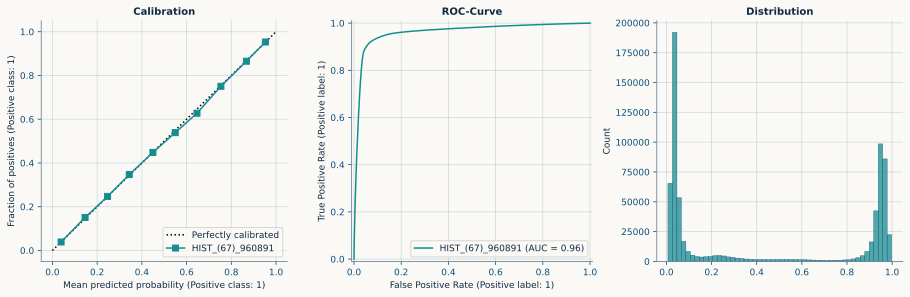

In [42]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

# for ax in axs:
#     ax.legend(loc='lower right')

plt.tight_layout(pad=0.2)
plt.show()

In [43]:
try:
    import shap
except:
    !uv pip install -q shap
    import shap

print(f"Shap version: {shap.__version__}")

Shap version: 0.52.0


In [44]:
feat_names = X_val.columns
print(f"Model pipeline features: {len(feat_names)}")

x_val = X_val.to_numpy() # convert sparze to numpy

# Randomly select 100 rows without replacement
rng = np.random.default_rng(seed=42)
indices = rng.choice(x_val.shape[0], size=100, replace=False)
val_x = x_val[indices]
val_y = y.values[indices]

## -- Shap Explainer --
def f(x):
    return model.predict_proba(x)[:, 1]

val_y

Model pipeline features: 67


array([1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0,
       1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1], dtype=int32)

PermutationExplainer explainer: 101it [01:18,  1.23it/s]                         


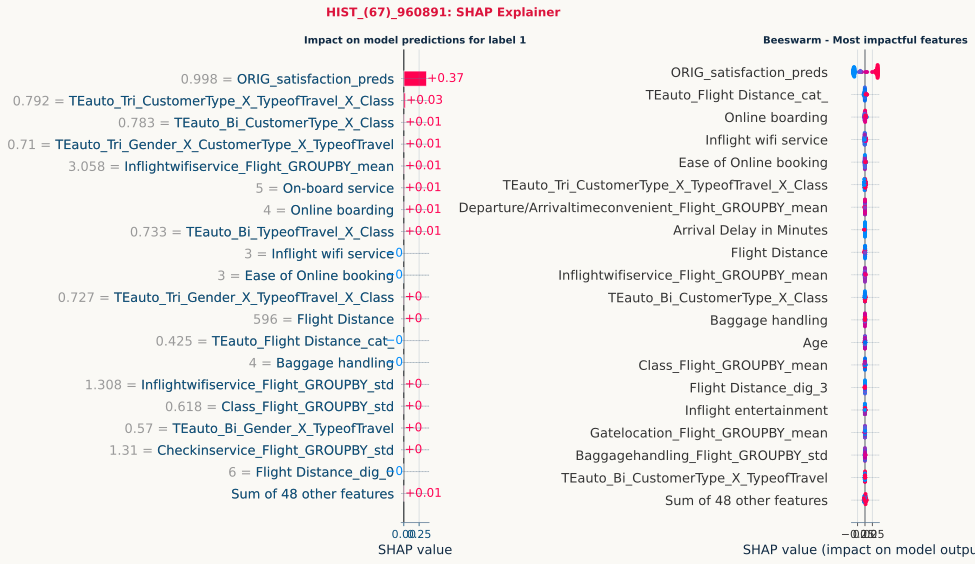

In [45]:
_id = 1
MAX = 20

explainer   = shap.Explainer(f, val_x, feature_names=feat_names, seed=42)
explanation = explainer(val_x, max_evals=max(500, 2*val_x.shape[1]+1))

## -- Bar plot --
plt.subplot(121)
shap.plots.bar(explanation[_id], max_display=MAX, show=False)
plt.title(f"Impact on model predictions for label {val_y[_id]}")

## -- Beeswarm plot --
plt.subplot(122)
shap.plots.beeswarm(
    explanation,
    order=explanation.abs.max(0),
    plot_size=(12.5, 8),
    max_display=MAX,
    color_bar=False,
    show=False,
)

plt.title("Beeswarm - Most impactful features")
plt.suptitle(f"{n}: SHAP Explainer", size=12, weight="semibold", color=CRIM)
plt.tight_layout(pad=1.5)
plt.show()

print()